# 05 | Warum schwankt mein Ergebnis?

Ein Punkt ist ein Versuch. Ein Lauf verarbeitet **N Punkte** und liefert
eine Pi-Schätzung. Eine Studie wiederholt den ganzen Lauf **R-mal**.
Mehr Punkte pro Lauf und mehr vollständige Läufe sind verschiedene Dinge.

**Lernziele:** N und R unterscheiden, Streuung und Standardfehler benennen,
ein Konfidenzintervall als Ergebnis eines wiederholbaren Verfahrens erklären.
**Vorwissen:** Trefferquote, Schleife, Funktion und Seed aus Termin 04.
**Ablauf:** vorbereitete Demo, dann zwei Aufgaben zu je 15 Minuten.
**Umgebung:** Kurs-Python mit Matplotlib und statsmodels. Alle Zellen sind
ohne Dateien oder Downloads ausführbar. Die Ausgangsfassung ist komplett;
eigene Antworten gehören in neue Zellen. Grafikcode darf als Werkzeug dienen.

In [41]:
from random import Random
import math
from statistics import mean, stdev

import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint

plt.rcParams.update({"font.size": 14})

## Erst sehen: Vier verschiedene Ergebnisse

Die vier vorbereiteten Werte unten illustrieren Schätzungen derselben Zahl.
Sie sind keine ausgeführte Simulationsstudie und kein Gütenachweis.
**Vorhersage:** Warum ist die Streuung der vier Punkte etwas anderes als
die Entfernung eines einzelnen Punktes zur Referenzlinie?

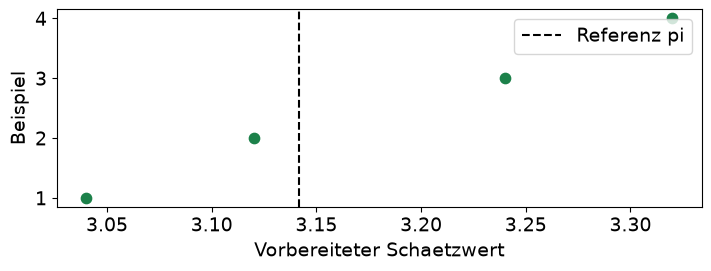

In [42]:
beispielwerte = [3.04, 3.12, 3.24, 3.32]
figur, achse = plt.subplots(figsize=(7, 2.6), layout="constrained")
achse.scatter(beispielwerte, [1, 2, 3, 4], color="#1c814a", s=55)
achse.axvline(math.pi, color="black", linestyle="--", label="Referenz pi")
achse.set(xlabel="Vorbereiteter Schaetzwert", ylabel="Beispiel", yticks=[1, 2, 3, 4])
achse.legend()
plt.show()
plt.close(figur)

Streuung beschreibt die Unterschiede **zwischen** den Schätzungen.
Die Standardabweichung fasst diese Unterschiede in einer Zahl mit derselben
Einheit wie die Schätzungen zusammen. `stdev` berechnet sie für uns;
ihre Formel müssen Sie heute nicht selbst programmieren.
Absoluter Fehler beschreibt die Entfernung **einer** Schätzung zur wahren
Zahl. In anderen Anwendungen kennen wir die wahre Zahl nicht und können
diesen Fehler nicht ausrechnen. Einen Standardfehler können wir dennoch
aus den simulierten Daten schätzen, sofern die Modellannahmen passen.

## 1. Zuerst feste Zahlen

Eine Ja/Nein-Beobachtung wird als 1 oder 0 codiert. Bei Trefferquote p
schätzen wir ihre Streuung durch sqrt(p * (1 - p)). Der Standardfehler
der **mittleren Trefferquote** ist sqrt(p * (1 - p) / N).
Für Pi werden Quote und Standardfehler mit 4 multipliziert.
Diese Plug-in-Formel setzt unabhängige Versuche mit gleicher Trefferchance
voraus. Bei null Treffern ergibt sie 0, obwohl die Chance unbekannt bleibt.

In [43]:
def standardfehler_treffer(treffer, anzahl):
    if anzahl <= 0 or not 0 <= treffer <= anzahl:
        raise ValueError("Gueltige Trefferzahl und positive Versuchszahl erforderlich")
    quote = treffer / anzahl
    return math.sqrt(quote * (1 - quote) / anzahl)


print("80/100: Quote", 80 / 100, "SE", standardfehler_treffer(80, 100))
print("320/400: Quote", 320 / 400, "SE", standardfehler_treffer(320, 400))

80/100: Quote 0.8 SE 0.04
320/400: Quote 0.8 SE 0.02


`math.sqrt` zieht die Quadratwurzel. Gleiche Quote, vierfaches N: aus
SE = 0.04 wird SE = 0.02. Die Streuung eines einzelnen 0/1-Werts bleibt
dagegen 0.4. Der Nenner N gehört zur Genauigkeit des Mittelwerts.
Bei einer echten Simulation bleibt die beobachtete Quote nicht genau gleich.
Daher ist die Halbierung eine typische Skalierung, kein Versprechen für
den absoluten Fehler jedes einzelnen Laufs.

## 2. Ein Lauf liefert eine Schätzung und ein Intervall

Die Trefferregel stammt aus Termin 04. Neu ist nur die Auswertung.
`proportion_confint(..., method="wilson")` ist eine getestete Bibliotheksfunktion
für ein Wilson-Intervall der Trefferwahrscheinlichkeit. `alpha=0.05`
bedeutet nominell 95% Konfidenz. Beide Intervallgrenzen werden für Pi mit
4 multipliziert, ebenso der Standardfehler der Trefferquote.

Das Ergebnis ist ein **Dictionary**: Namen wie `"schaetzung"` beschriften
die Zahlen. `ergebnis["schaetzung"]` liest den zugehörigen Wert.
Die geschweiften Klammern in `return` sammeln diese benannten Ergebnisse.

In [44]:
def pi_lauf(anzahl, seed):
    if anzahl <= 0:
        raise ValueError("anzahl muss positiv sein")
    generator = Random(seed)
    treffer = 0
    for versuch in range(anzahl):
        koordinate_x = generator.random()
        koordinate_y = generator.random()
        if koordinate_x ** 2 + koordinate_y ** 2 <= 1:
            treffer += 1
    untergrenze, obergrenze = proportion_confint(treffer, anzahl, alpha=0.05, method="wilson")
    return {
        "anzahl": anzahl,
        "seed": seed,
        "treffer": treffer,
        "schaetzung": 4 * treffer / anzahl,
        "standardfehler": 4 * standardfehler_treffer(treffer, anzahl),
        "untergrenze": 4 * float(untergrenze),
        "obergrenze": 4 * float(obergrenze),
    }


ergebnis = pi_lauf(200, 2026)
print(ergebnis)

{'anzahl': 200, 'seed': 2026, 'treffer': 150, 'schaetzung': 3.0, 'standardfehler': 0.1224744871391589, 'untergrenze': 2.7426360675181667, 'obergrenze': 3.2196732797272998}


## 3. Nicht denselben Lauf vierzigmal kopieren

Jeder Lauf startet mit einem eigenen Seed. Für das Lehrmodell behandeln wir
die Folgen als unabhängige Wiederholungen. Unterschiedliche Seeds allein
beweisen keine statistische Unabhängigkeit; sie vermeiden hier das bloße
Kopieren desselben Laufs. Neue Generatoren entstehen pro Lauf, nicht pro Punkt.
`append` hängt ein Ergebnis an die Liste. Die Liste enthält R Dictionaries,
nicht N Punkte. Für genaüre Streamplanung folgt später SeedSeqünce.

In [45]:
def pi_studie(anzahl, wiederholungen, startseed):
    if anzahl <= 0 or wiederholungen <= 0:
        raise ValueError("anzahl und wiederholungen muessen positiv sein")
    ergebnisse = []
    for laufnummer in range(wiederholungen):
        ergebnisse.append(pi_lauf(anzahl, startseed + laufnummer))
    return ergebnisse


ergebnisse = pi_studie(200, 40, 1000)
print("N =", ergebnisse[0]["anzahl"], "R =", len(ergebnisse))
print("Alle Punkte der Studie:", ergebnisse[0]["anzahl"] * len(ergebnisse))

N = 200 R = 40
Alle Punkte der Studie: 8000


`ergebnisse[0]` ist der erste Lauf: Python beginnt bei Index 0.
`len(ergebnisse)` liefert R. Die beobachtete Streuung dieser R Schätzungen
beschreibt die typische Schwankung **eines Laufs mit N Punkten**.
**Vertiefung, nicht für die Pflichttabelle:** Teilen wir diese Streuung
zusätzlich durch sqrt(R), erhalten wir den
geschätzten SE des **Mittelwerts aller R Laufergebnisse**. Das ist eine
andere Schätzung mit dem R-fachen Budget. Die zwei Zahlen nie gleich benennen.
`stdev` berechnet die Stichproben-Standardabweichung mit Nenner R - 1;
dazu brauchen wir mindestens zwei Läufe.

In [46]:
def studienkennzahlen(ergebnisse):
    if len(ergebnisse) < 2:
        raise ValueError("Mindestens zwei Laufergebnisse erforderlich")
    schaetzungen = []
    breiten = []
    for ergebnis in ergebnisse:
        schaetzungen.append(ergebnis["schaetzung"])
        breiten.append(ergebnis["obergrenze"] - ergebnis["untergrenze"])
    streuung = stdev(schaetzungen)
    return {
        "mittelwert": mean(schaetzungen),
        "streuung_eines_laufs": streuung,
        "se_des_mittelwerts_aller_laeufe": streuung / math.sqrt(len(ergebnisse)),
        "mittlere_intervallbreite": mean(breiten),
    }


kennzahlen = studienkennzahlen(ergebnisse)
print("Streuung der Laufschaetzungen:", kennzahlen["streuung_eines_laufs"])
print("Mittlere Intervallbreite:", kennzahlen["mittlere_intervallbreite"])

Streuung der Laufschaetzungen: 0.12016975172966458
Mittlere Intervallbreite: 0.4487712811988622


## 4. Auswertung als Tabelle und Bild

Die Tabelle zeigt zuerst fünf vollständige Läufe. `round` rundet nur die
Anzeige. `ergebnisse[:5]` wählt die ersten fünf Einträge.
Im linken Bild steht ein Punkt für einen vollständigen Lauf. Der Balken
ist sein Wilson-Intervall, **nicht** die Streuung seiner einzelnen Punkte.
Rechts zählen Balken, wie viele der R Schätzungen in einem Zahlenbereich
liegen. Das ist ein Histogramm von Schätzungen, kein Punktbild im Quadrat.

Seed | N | Schaetzung | SE Pi | Untergrenze | Obergrenze
1000 200 2.94 0.1248 2.6793 3.1653
1001 200 3.18 0.1142 2.935 3.3806
1002 200 3.08 0.119 2.8277 3.2916
1003 200 3.22 0.1121 2.9782 3.4158
1004 200 2.94 0.1248 2.6793 3.1653


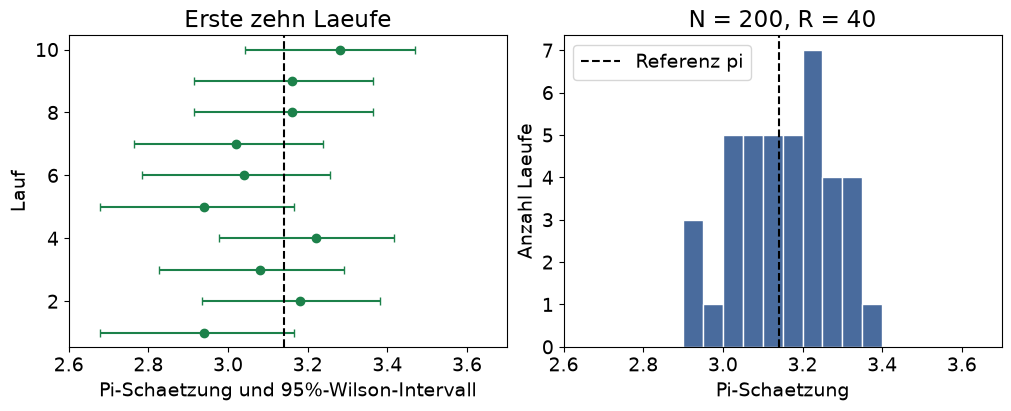

In [47]:
print("Seed | N | Schaetzung | SE Pi | Untergrenze | Obergrenze")
for ergebnis in ergebnisse[:5]:
    print(ergebnis["seed"], ergebnis["anzahl"], round(ergebnis["schaetzung"], 4),
          round(ergebnis["standardfehler"], 4), round(ergebnis["untergrenze"], 4),
          round(ergebnis["obergrenze"], 4))


def zeige_studie(ergebnisse):
    figur, achsen = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
    for laufnummer, ergebnis in enumerate(ergebnisse[:10], start=1):
        abstand_links = ergebnis["schaetzung"] - ergebnis["untergrenze"]
        abstand_rechts = ergebnis["obergrenze"] - ergebnis["schaetzung"]
        achsen[0].errorbar(ergebnis["schaetzung"], laufnummer,
                          xerr=[[abstand_links], [abstand_rechts]],
                          fmt="o", capsize=3, color="#1c814a")
    achsen[0].axvline(math.pi, color="black", linestyle="--")
    achsen[0].set(xlabel="Pi-Schaetzung und 95%-Wilson-Intervall", ylabel="Lauf",
                  title="Erste zehn Laeufe", xlim=(2.6, 3.7))
    schaetzungen = []
    for ergebnis in ergebnisse:
        schaetzungen.append(ergebnis["schaetzung"])
    grenzen = [2.6 + schritt * 0.05 for schritt in range(23)]
    achsen[1].hist(schaetzungen, bins=grenzen, color="#496b9d", edgecolor="white")
    achsen[1].axvline(math.pi, color="black", linestyle="--", label="Referenz pi")
    achsen[1].set(xlabel="Pi-Schaetzung", ylabel="Anzahl Laeufe", xlim=(2.6, 3.7),
                  title=f"N = {ergebnisse[0]['anzahl']}, R = {len(ergebnisse)}")
    achsen[1].legend()
    plt.show()
    plt.close(figur)


zeige_studie(ergebnisse)

**So wird das Intervall gelesen:** Die wahre Zielzahl ist fest; die
Intervallgrenzen wechseln von Lauf zu Lauf. Unter dem Modell soll das
Verfahren bei vielen unabhängigen Wiederholungen ungefähr 95% der
Intervalle so erzeugen, dass sie die Zielzahl enthalten. Wilson erreicht
wegen diskreter Trefferzahlen nicht für jedes N und jede Chance exakt 95%.
Es bedeutet weder "95% der Punkte liegen im Intervall" noch eine
95%-Wahrscheinlichkeit für die feste Zielzahl nach diesem Lauf.
Auch ein korrekt berechnetes Intervall kann die Referenz verfehlen.

**Keine Aussage über Modellfehler:** Wenn die Punkte nicht gleichverteilt
im Quadrat gezogen werden, kann ein enges Intervall das falsche Ziel treffen.
Ein SE ist außerdem nicht die beobachtete Abweichung zu `math.pi`.

## Eigenarbeit | 30 Minuten

**A05.1 | 15 Minuten:** Lesen Sie für die ersten drei Läufe N, Seed,
Schätzung, SE und die beiden Intervallgrenzen ab. Beschreiben Sie den
Unterschied zwischen einem Punkt, einem Lauf und der ganzen Studie.
Benennen Sie anschließend im linken Bild einen Schätzwert und seine
Grenzen. Formulieren Sie einen korrekten Satz zur Bedeutung des Intervalls.

**A05.2 | 15 Minuten:** Wiederholen Sie die Studie mit N = 800, R = 40
und demselben Startseed. Vergleichen Sie die Streuung der Schätzungen und
die mittlere Intervallbreite. Muss jeder größere Lauf näher an Pi liegen?
Die zwei Studien sind wegen gleicher Seeds gepaart; sie werden nicht als
voneinander unabhängige Studien ausgegeben.

**Hilfe:** `groessere_studie = pi_studie(800, 40, 1000)` erzeugt die Daten.
Verwenden Sie danach `studienkennzahlen(groessere_studie)` und
`zeige_studie(groessere_studie)`. Vergleichen Sie beide Histogramme bei
gleicher Achsenskala. Das Zeichnen der Grafik ist keine Zusatzprogrammieraufgabe.
Für die Pflichttabelle genügen `streuung_eines_laufs` und
`mittlere_intervallbreite` (obere minus untere Grenze). Die anderen
Rückgabewerte sind eine Vertiefung. Ein Histogramm allein ordnet die
einzelnen Paare nicht zu; die Garantiefrage begründen Sie wie in 04.
Es ist keine neue Programmierschleife verlangt.

## Drei Dinge bleiben

1. N zählt Versuche pro Lauf; R zählt vollständige Läufe.
2. Der SE beschreibt die typische Schwankung einer Schätzung, nicht ihren
   bekannten exakten Fehler. Vierfaches N halbiert den typischen SE.
3. Konfidenz gehört zum Verfahren unter Annahmen, nicht zu einer Garantie
   für einen konkreten Lauf und nicht zu einer Prüfung aller Modellfehler.

**Abschlussfrage:** Werden einzelne Läufe präziser, wenn nur R steigt?
Nein. Nur der gemeinsame Mittelwert vieler Läufe wird typischerweise präziser.
**Nächster Termin:** Statt 0/1-Treffern mitteln wir Funktionshöhen.

## Wahlteil | Null Treffer und mathematische Voraussetzungen

Diese Zellen gehören nicht zur Pflichtzeit. Keine Formeln auswendig lernen.
Bei null Treffern in 100 Versuchen ist die beobachtete Quote 0. Der
Plug-in-SE wird ebenfalls 0. Ein Wald-Intervall "Quote +/- 1.96 * SE"
würde fälschlich [0, 0] liefern. Wilson hat eine positive obere Grenze.
Hier betrachten wir eine allgemeine Trefferchance, nicht einen Pi-Lauf.

# A05.1
| Lauf | N | Seed | Schätzung | SE | Untergrenze | Obergrenze |
|---:|---:|---:|---:|---:|---:|---:|
| 1 | 200 | 1000 | 2,94 | 0,1248 | 2,6793 | 3,1653 |
| 2 | 200 | 1001 | 3,18 | 0,1142 | 2,9350 | 3,3806 |
| 3 | 200 | 1002 | 3,08 | 0,1190 | 2,8277 | 3,2916 |
 Ein Punkt ist ein zufälliger x und y-Wert, der sich innerhalb oder ausserhalb des Einheitskreises befindet. 
 Ein Lauf besteht aus einer bestimmten Anzahl von Punkten, die generiert werden, um Pi zu schätzen.
 Die Trefferquote ist die Anzahl der Punkte, die innerhalb des Kreises liegen, geteilt durch die Gesamtzahl der Punkte. 
 Die Schätzung von Pi wird dann als 4 mal die Trefferquote berechnet.

# A05.2
Auswertung A05.2: Bei N = 200 beträgt die Streuung der Schätzungen etwa 0,1202 und die mittlere Intervallbreite 0,4488. Bei N = 800 sind es etwa 0,0584 und 0,2268. In dieser Studie sind Streuung und Intervallbreite mit 800 Punkten geringer.

Das bedeutet nicht, dass jeder einzelne größere Lauf näher an pi liegt. Zum Beispiel liegt Seed 1001 bei N = 200 mit 3,18 näher an pi als bei N = 800 mit 3,21. Die zwei Studien sind durch die gleichen Seeds gepaart; dieser Vergleich behandelt sie daher nicht als unabhängige Studien.

In [49]:
print("Plug-in-SE bei null Treffern:", standardfehler_treffer(0, 100))
print("95%-Wilson bei null Treffern:", proportion_confint(0, 100, alpha=0.05, method="wilson"))
abgedeckt = 0
for ergebnis in ergebnisse:
    if ergebnis["untergrenze"] <= math.pi <= ergebnis["obergrenze"]:
        abgedeckt += 1
print("Referenz im Intervall:", abgedeckt, "von", len(ergebnisse))

Plug-in-SE bei null Treffern: 0.0
95%-Wilson bei null Treffern: (0.0, 0.03699349820698569)
Referenz im Intervall: 40 von 40


Dieser beobachtete Anteil aus nur R = 40 Läufen ist kein Beweis für 95%
Deckung. Für eine Deckungsstudie bräuchten wir mehr unabhängige Läufe
und selbst wieder eine Unsicherheitsangabe für den gemessenen Anteil.

**Gesetz der großen Zahlen (LLN):** Bei unabhängigen identisch verteilten
Beobachtungen mit endlichem Erwartungswert des Absolutbetrags stabilisiert
sich der Mittelwert. Dafür ist endliche Varianz nicht zwingend erforderlich.
**Zentraler Grenzwertsatz (CLT), hier in der Standardform:** Bei denselben
Unabhängigkeitsannahmen und endlicher positiver Varianz wird der normierte
Mittelwert asymptotisch normal. Sehr große Ausreißer können die Annäherung
langsam machen. Für die Cauchy-Verteilung fehlt schon der benötigte
Erwartungswert; "genug N repariert alles" ist falsch.

Wilson ist auf unabhängige Bernoulli-Versuche zugeschnitten. Für andere
Zielgrößen und abhängige Daten brauchen wir passende Auswertungen.